# Forest Fires

This dataset is provided by [UCI Machine Learning](https://archive.ics.uci.edu/ml/datasets/forest+fires).  and has been taken from [Kaggle](https://www.kaggle.com/elikplim/forest-fires-data-set). 
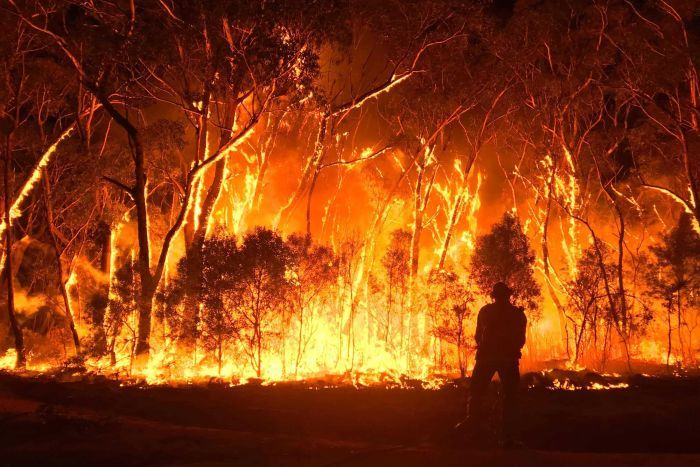<h5><center>Source: abc.net.au</center></h5>
                                              

# Problem Statement:

The recent ecological disasters in Australisa and Brazil have resurfaced the discussion surrounding forest fires and ways to mitigate them. Data Science is one of elements of the toolbox that is required to fight this danger. In this data tale, we are going to see how Data Science and Machine Learning will help in solving the problem. We will try to predict the area burned by forest fire, given the meteorological and spatio-temporal data for fire in Portugal's Montesinho Natural Park. For more information, read the [paper](www3.dsi.uminho.pt/pcortez/fires.pdf) published on it. 

**Hence, this is a regression problem. We can thus apply the following machine learning algorithms: <br>
a) Linear Regression <br>
b) Decision Tree <br>
c) SVM <br>
d) RandomForest <br>
e) Ensembling methods like ADA Boost, Gradient Boost, XGBoost <br>**


# DATA DESCRIPTION:

The data set consists of 13 variables. Our target variable is "area" i.e the area of forest burned by the fire. The other 12 variables are spatial, temporal and meteorological features. 

## Attributes:
1. X - x-axis spatial coordinate within the Montesinho park map: 1 to 9
2. Y - y-axis spatial coordinate within the Montesinho park map: 1 to 9
3. month - month of the year: "jan" to "dec"
4. day - day of the week: "mon" to "sun"
5. FFMC - Fine Fuel Moisture Code. It denotes the moisture content in the surface litter and thus influences ignition and Fire Spread: 18.7 to 96.20
6. DMC - Duff Moisture Code. It denotes the moisture content of shallow organic layers. It influences fire intensity: 1.1 to 291.3
7. DC - Drought Code. It denotes the moisture content of deep organic layers. It influences fire intensity: 7.9 to 860.6
8. ISI - Initial Spread Index. It correlates with the fire velocity spread: 0.0 to 56.10
9. temp - temperature in Celsius degrees: 2.2 to 33.30
10. RH - relative humidity in %: 15.0 to 100
11. wind - wind speed in km/h: 0.40 to 9.40
12. rain - Accumulated precipitation in the previous 30 minutes, in mm/m2 : 0.0 to 6.4
13. area - the burned area of the forest (in ha): 0.00 to 1090.84. 
<br> **NOTE: 0 indicates that the burned area was less than 100 m2)**

The FWI system is the Canadian System of rating fire danger. FFMC, DMC, DC, ISI, Buildup Index (BUI) are part of the FWI system. However, BUI is dependent on DMC and DC. So, to avoid multi-collinearity, it was excluded from the data set itself.

# Performance Measure

As it is a regression problem, we will use **R-Square** as the Performance Measure. Higher the R2, better the model.

In [1]:
# Import the required packages that we require

#Basic Python
import pandas as pd
import numpy as np

#Visualisation Packages
import matplotlib.pyplot as plt
plt.style.use('ggplot')
import seaborn as sns
%matplotlib inline 


# DATA PRE-PROCESSING:

1. Read Data
2. Data Cleaning: Look for null values, duplicates and take necessary actions. 

In [2]:
# 1. Reading and Inspecting Data
fire_df = pd.read_csv('forestfires.csv')
fire_df.sample(5)

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
384,8,4,aug,sat,91.6,273.8,819.1,7.7,21.3,44,4.5,0.0,12.18
418,2,4,aug,sun,92.0,203.2,664.5,8.1,24.9,42,5.4,0.0,2.44
162,6,3,mar,sat,90.6,50.1,100.4,7.8,15.2,31,8.5,0.0,1.94
334,2,3,sep,mon,91.6,108.4,764.0,6.2,18.0,51,5.4,0.0,0.00
224,7,4,sep,wed,90.1,82.9,735.7,6.2,15.4,57,4.5,0.0,37.71


In [3]:
fire_df.shape

(517, 13)

In [4]:
categorical_columns = ['month','day','X','Y']
numerical_columns = list(set(fire_df.columns) - set(categorical_columns)-set(['area']))
target = fire_df.area

## 2.  Data Cleaning: Checking Missing and Faulty values.

In [5]:
#Check for duplicates
fire_df.duplicated().sum()

4

In [6]:
#Removing duplicates
fire_df.drop_duplicates(inplace=True)
fire_df.shape

(513, 13)

In [7]:
#Check for nulls
fire_df.isnull().sum()

X        0
Y        0
month    0
day      0
FFMC     0
DMC      0
DC       0
ISI      0
temp     0
RH       0
wind     0
rain     0
area     0
dtype: int64

In [8]:
#No Faulty values in Month variable
fire_df.month.value_counts()

aug    182
sep    172
mar     53
jul     32
feb     20
jun     16
oct     15
apr      9
dec      9
jan      2
may      2
nov      1
Name: month, dtype: int64

In [9]:
#No Faulty values in day variable
fire_df.day.value_counts()

sun    94
fri    84
sat    83
mon    74
tue    64
thu    61
wed    53
Name: day, dtype: int64

In [10]:
#No Faulty values in X variable
fire_df.X.value_counts()

4    89
6    86
2    73
8    61
7    60
3    53
1    48
5    30
9    13
Name: X, dtype: int64

In [11]:
#No Faulty values in Y variable
fire_df.Y.value_counts()

4    201
5    125
6     73
3     63
2     44
9      6
8      1
Name: Y, dtype: int64

In [12]:
fire_df.describe()

,X,Y,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
count,513.000000,513.000000,513.000000,513.000000,513.000000,513.000000,513.000000,513.000000,513.000000,513.000000,513.000000
mean,4.678363,4.300195,90.637427,110.989279,549.155166,9.023587,18.887524,44.348928,4.010526,0.021832,12.891598
std,2.320059,1.230925,5.540920,64.191013,247.724594,4.575543,5.828128,16.358803,1.796613,0.297107,63.892586
min,1.000000,2.000000,18.700000,1.100000,7.900000,0.000000,2.200000,15.000000,0.400000,0.000000,0.000000
25%,3.000000,4.000000,90.200000,68.600000,440.900000,6.400000,15.500000,33.000000,2.700000,0.000000,0.000000
50%,4.000000,4.000000,91.600000,108.300000,664.500000,8.400000,19.300000,42.000000,4.000000,0.000000,0.540000
75%,7.000000,5.000000,92.900000,142.400000,713.900000,11.000000,22.800000,53.000000,4.900000,0.000000,6.570000
max,9.000000,9.000000,96.200000,291.300000,860.600000,56.100000,33.300000,100.000000,9.400000,6.400000,1090.840000


All numerical columns are within the ranges specified in the data description. However, looks like the area variable is extremely skewed. We will look into this in the EDA section. 

# EDA
We will perform Univariate, bi-variate and multi-variate analysis over following steps in this section:
1. Explore the target feature.
2. Explore the categorical features and how they affect the target feature. 
3. Explore the numerical features and how they affect the target feature. 

Skew: 12.802213419146321
Kurtosis: 192.73391233370953


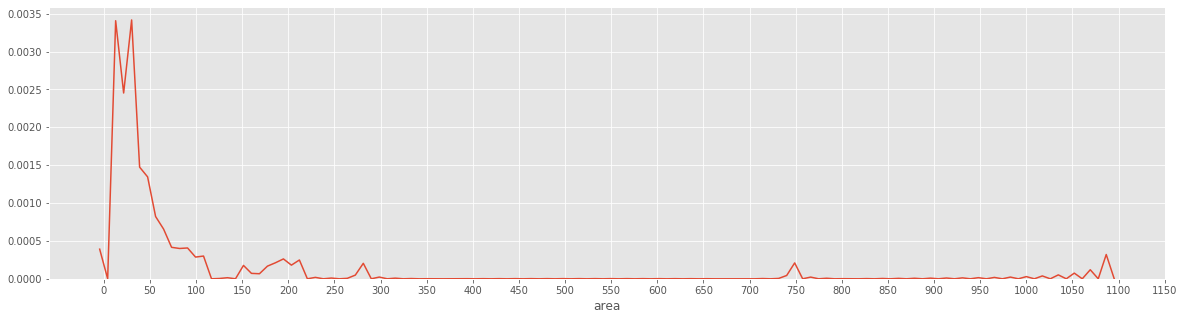

In [13]:
#Exploring the target feature. 
plt.figure(figsize=(20,5))
print("Skew: {}".format(fire_df.area.skew()))
print("Kurtosis: {}".format(fire_df.area.kurtosis()))
sns.distplot(fire_df.area, kde=True, hist=False)
plt.xticks([i for i in range(0,1200,50)])
plt.show()

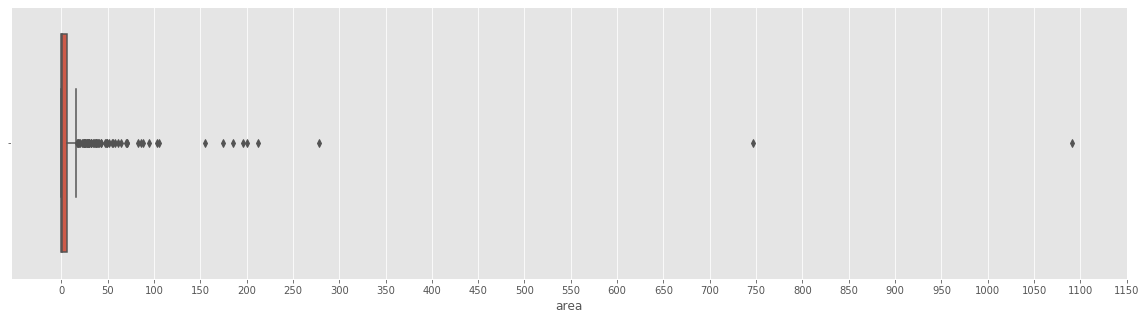

In [14]:
plt.figure(figsize=(20,5))
sns.boxplot(fire_df.area)
plt.xticks([i for i in range(0,1200,50)])
plt.show()

In [15]:
#Outliers
from scipy.stats import zscore
y_outliers = fire_df[abs(zscore(fire_df['area'])) >= 3 ]
y_outliers

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
237,1,2,sep,tue,91.0,129.5,692.6,7.0,18.8,40,2.2,0.0,212.88
238,6,5,sep,sat,92.5,121.1,674.4,8.6,25.1,27,4.0,0.0,1090.84
415,8,6,aug,thu,94.8,222.4,698.6,13.9,27.5,27,4.9,0.0,746.28
479,7,4,jul,mon,89.2,103.9,431.6,6.4,22.6,57,4.9,0.0,278.53


<font color='red'> **Challenges:** </font> 
1. Highly skewed target variable. 
2. Presence of Outliers. 

We would have to perform log transform and remove outliers to address this.

**However we can derive few insights:**
1. Most of the forest fires are of moderate area. In fact 75% of the forest fires affected less than 7 hectares of area. There are only few that become disastrous. 


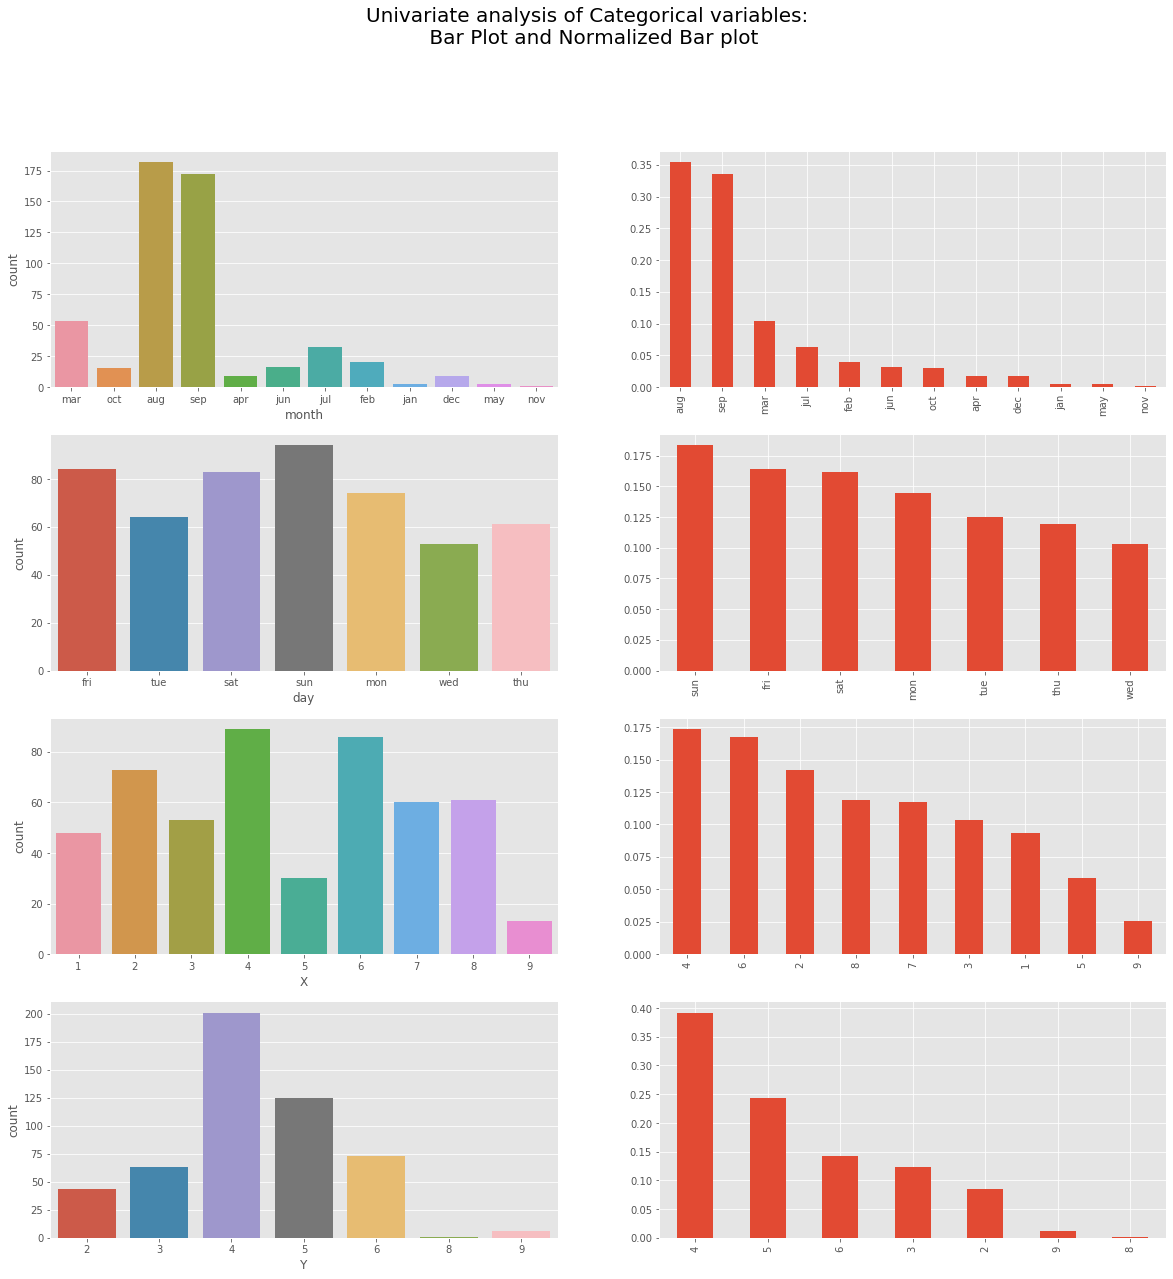

In [16]:
# 2. Exploring Categorical Variables.  
figure, axes = plt.subplots(4,2,figsize=(20,20),facecolor='white',squeeze=True)
axes = axes.flatten()
figure.suptitle('Univariate analysis of Categorical variables: \n Bar Plot and Normalized Bar plot', size=20)
index=0
for i in categorical_columns:
    sns.countplot(x= i ,data=fire_df, ax=axes[index])
    index = index+1
    fire_df[i].value_counts(normalize=True).plot(kind='bar', ax=(axes[index]))
    index = index+1       


**Insights:**
1. Most of the fires are in the months of august and september. 
2. More fires are on the weekends than on weekdays. This helps us in making a conclusion that there is human factor as well responsible for forest fires. 
3. Few pockets of the Natural Park recorded more forest fires. This can be because of the tree composition over there. 

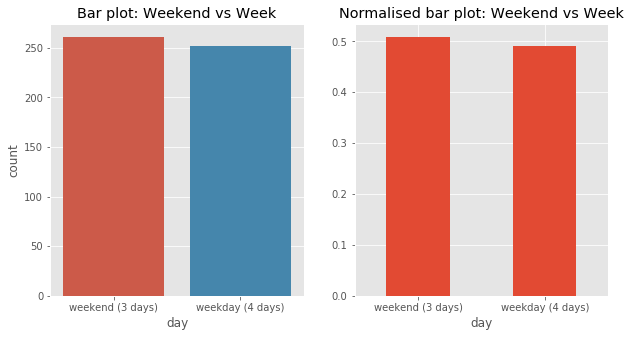

In [17]:
fil = (fire_df.day == 'fri') | (fire_df.day == 'sat') | (fire_df.day == 'sun')
fil2 = (fire_df.day == 'tue') | (fire_df.day == 'mon') | (fire_df.day == 'wed') | (fire_df.day=='thu')
weekend = fire_df.day.copy()
weekend[fil] = 'weekend (3 days)'
weekend[fil2] = 'weekday (4 days)'

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.countplot(weekend)
plt.title('Bar plot: Weekend vs Week')

plt.subplot(1,2,2)
weekend.value_counts(normalize=True).plot(kind='bar')
plt.xticks(rotation=0)
plt.xlabel('day')
plt.title('Normalised bar plot: Weekend vs Week')

plt.show()

So the forest forces should be vigilant in the months August and September, especially on the weekends to fight forest fires. 

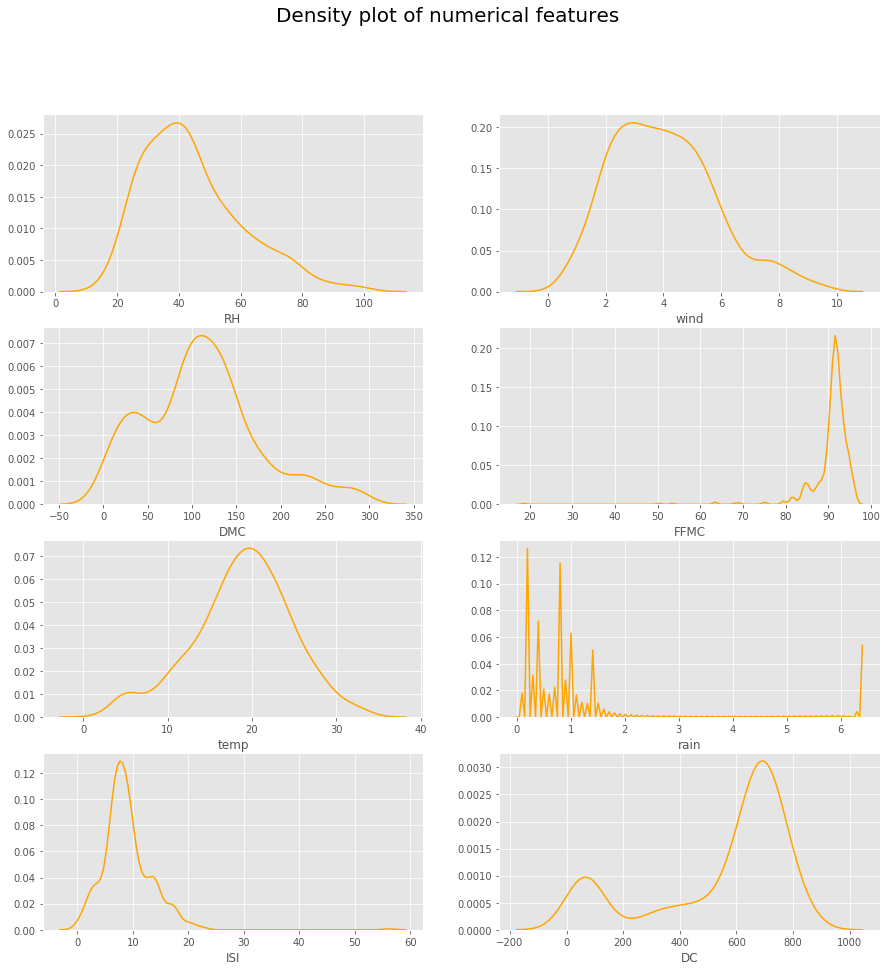

In [18]:
#3. Exploring Numerical Variables

fig, ax = plt.subplots(4, 2, figsize=(15, 15),squeeze=True)
ax = ax.flatten()
index = 0
fig.suptitle('Density plot of numerical features',size=20)

for i in numerical_columns:
    sns.distplot(fire_df[i], kde=True, color = 'orange',ax=ax[index],hist=False)
    index +=1
plt.show()

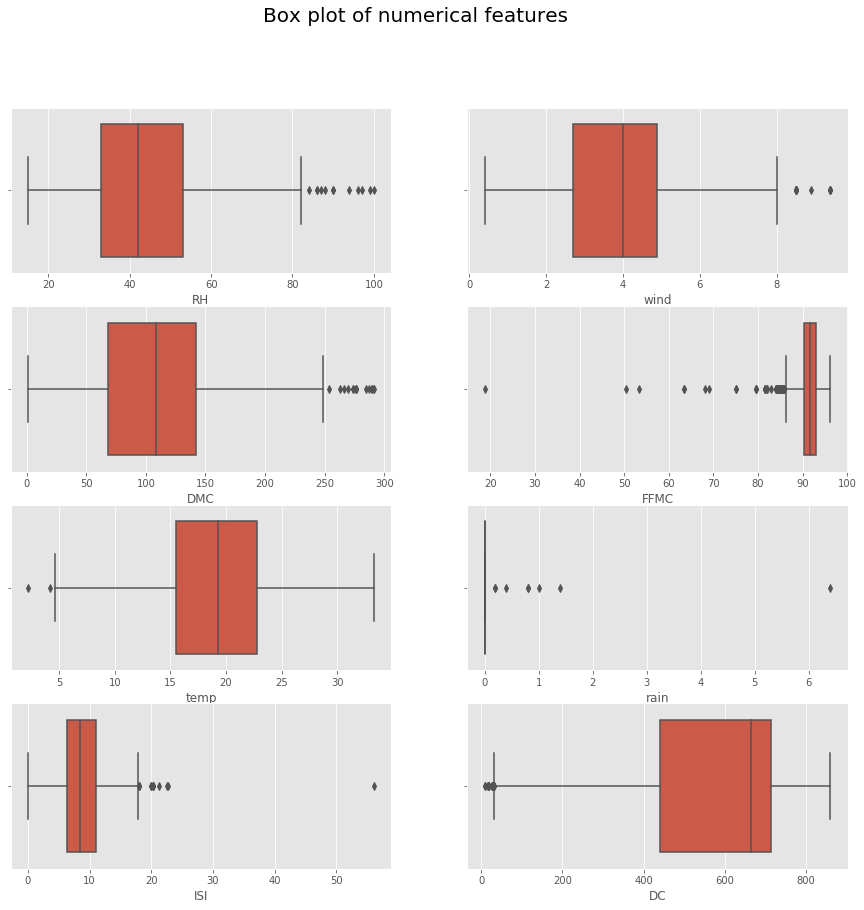

In [19]:
fig, ax = plt.subplots(4, 2, figsize=(15, 14),squeeze=True)
ax = ax.flatten()
index = 0
fig.suptitle('Box plot of numerical features',size=20)

for i in numerical_columns:
    sns.boxplot(fire_df[i],ax=ax[index])
    index +=1
plt.show()

<font color='red'> **Challenges:** </font> 
3. Highly skewed feature variables - FFMC, ISI
4. High kurtosis in rain feature
2. Presence of Outliers in rain, FFMC, ISI

In [20]:
#. We will do more univariate analysis, but increase level of detail. 
fire_df['Measure of Danger']=pd.cut(fire_df.area, [-1,1,10,50,100,1091], labels=['Negligible Fire','Minor Fire','Serious Fire','Major Fire','Disaster'])

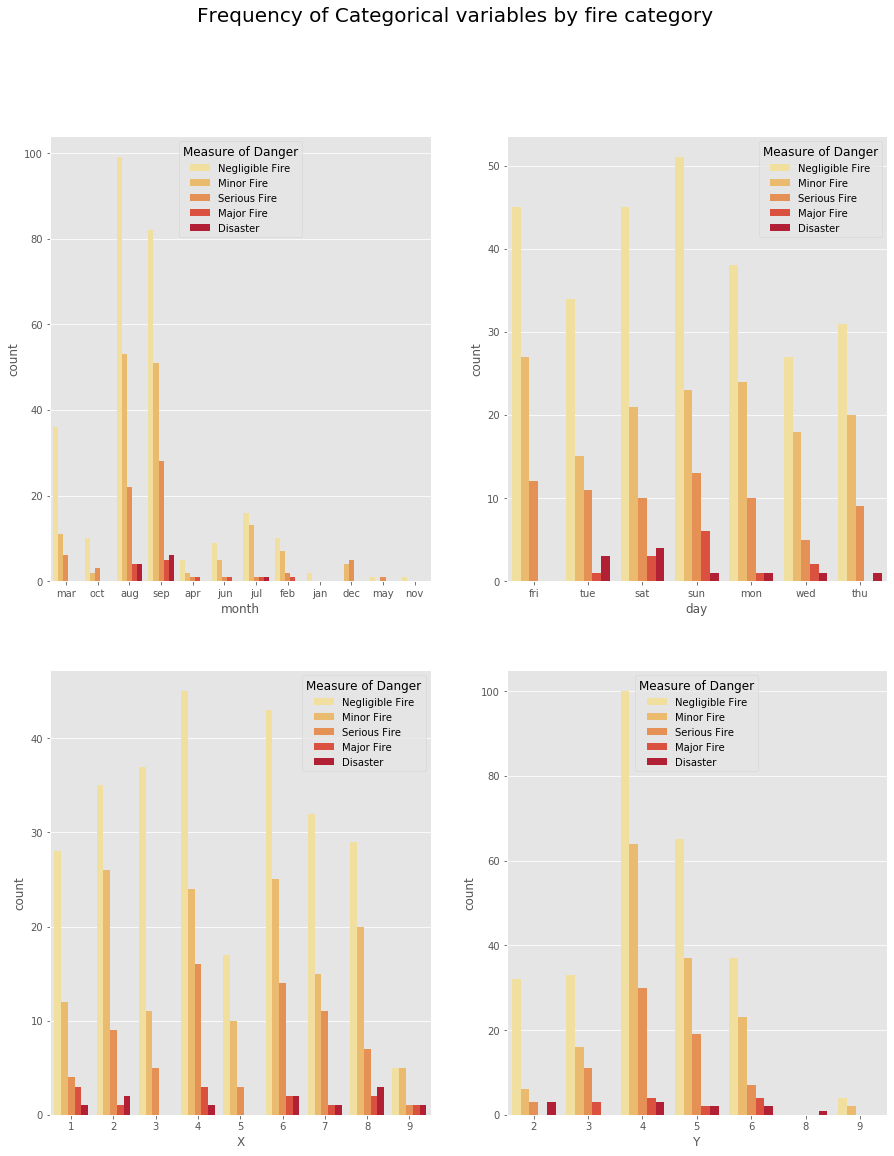

In [21]:
figure, axes = plt.subplots(2, 2, figsize=(15, 18),facecolor='white')
axes = axes.flatten()
figure.suptitle('Frequency of Categorical variables by fire category', size=20)

index=0
for col_name in categorical_columns:
    sns.countplot(x=col_name, hue='Measure of Danger',data=fire_df, ax=axes[index],palette='YlOrRd')
    index = index+1    

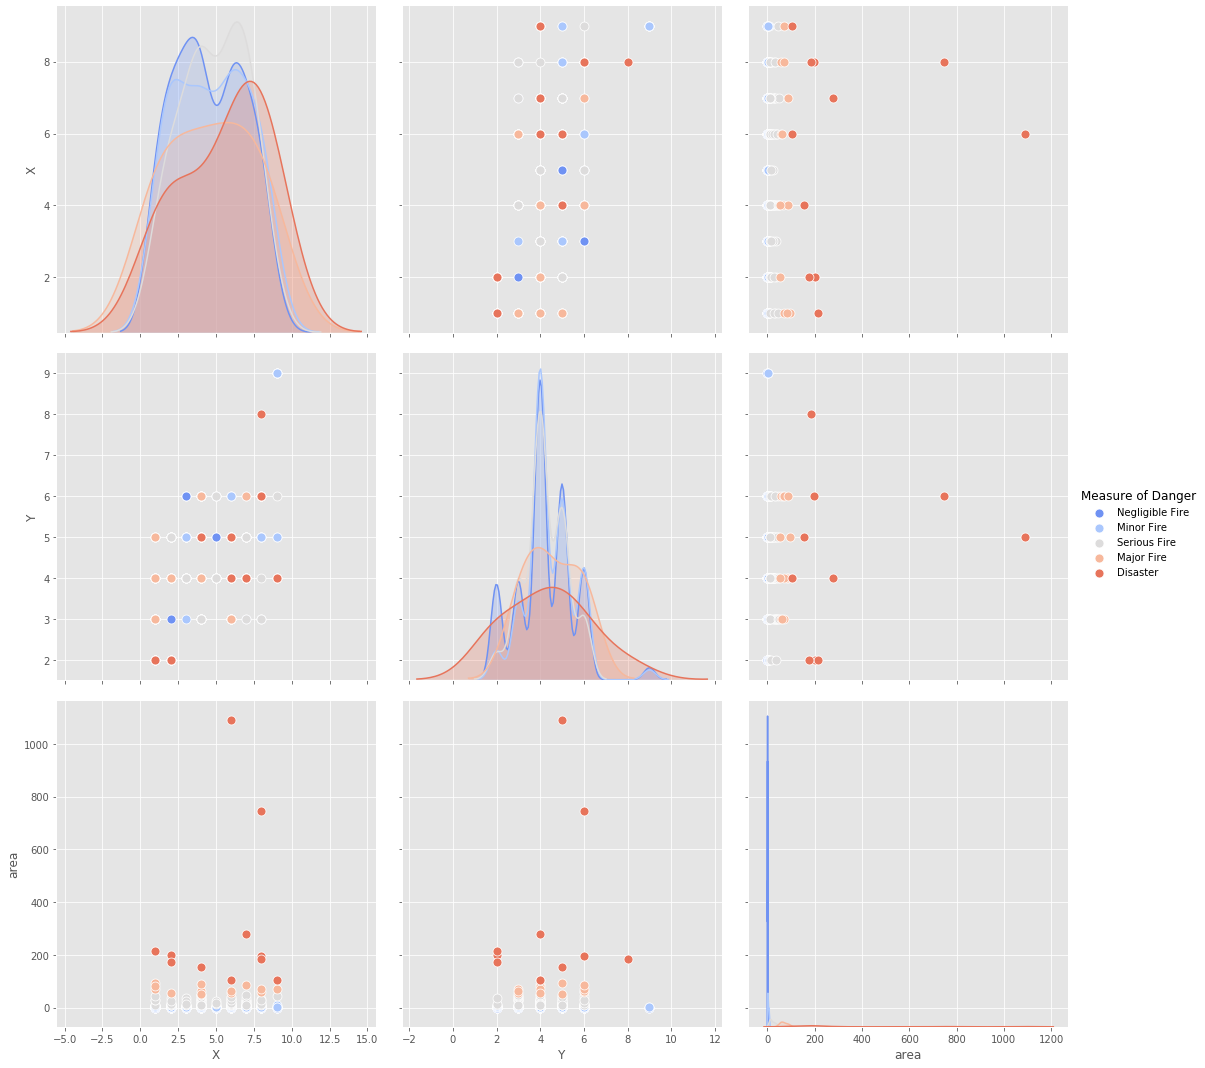

In [22]:
#Bi-variate analysis of Co-ordinates.
sns.pairplot(fire_df,hue='Measure of Danger',palette='coolwarm', vars=['X',"Y",'area'],height=5,plot_kws = { 's': 80})
plt.show()

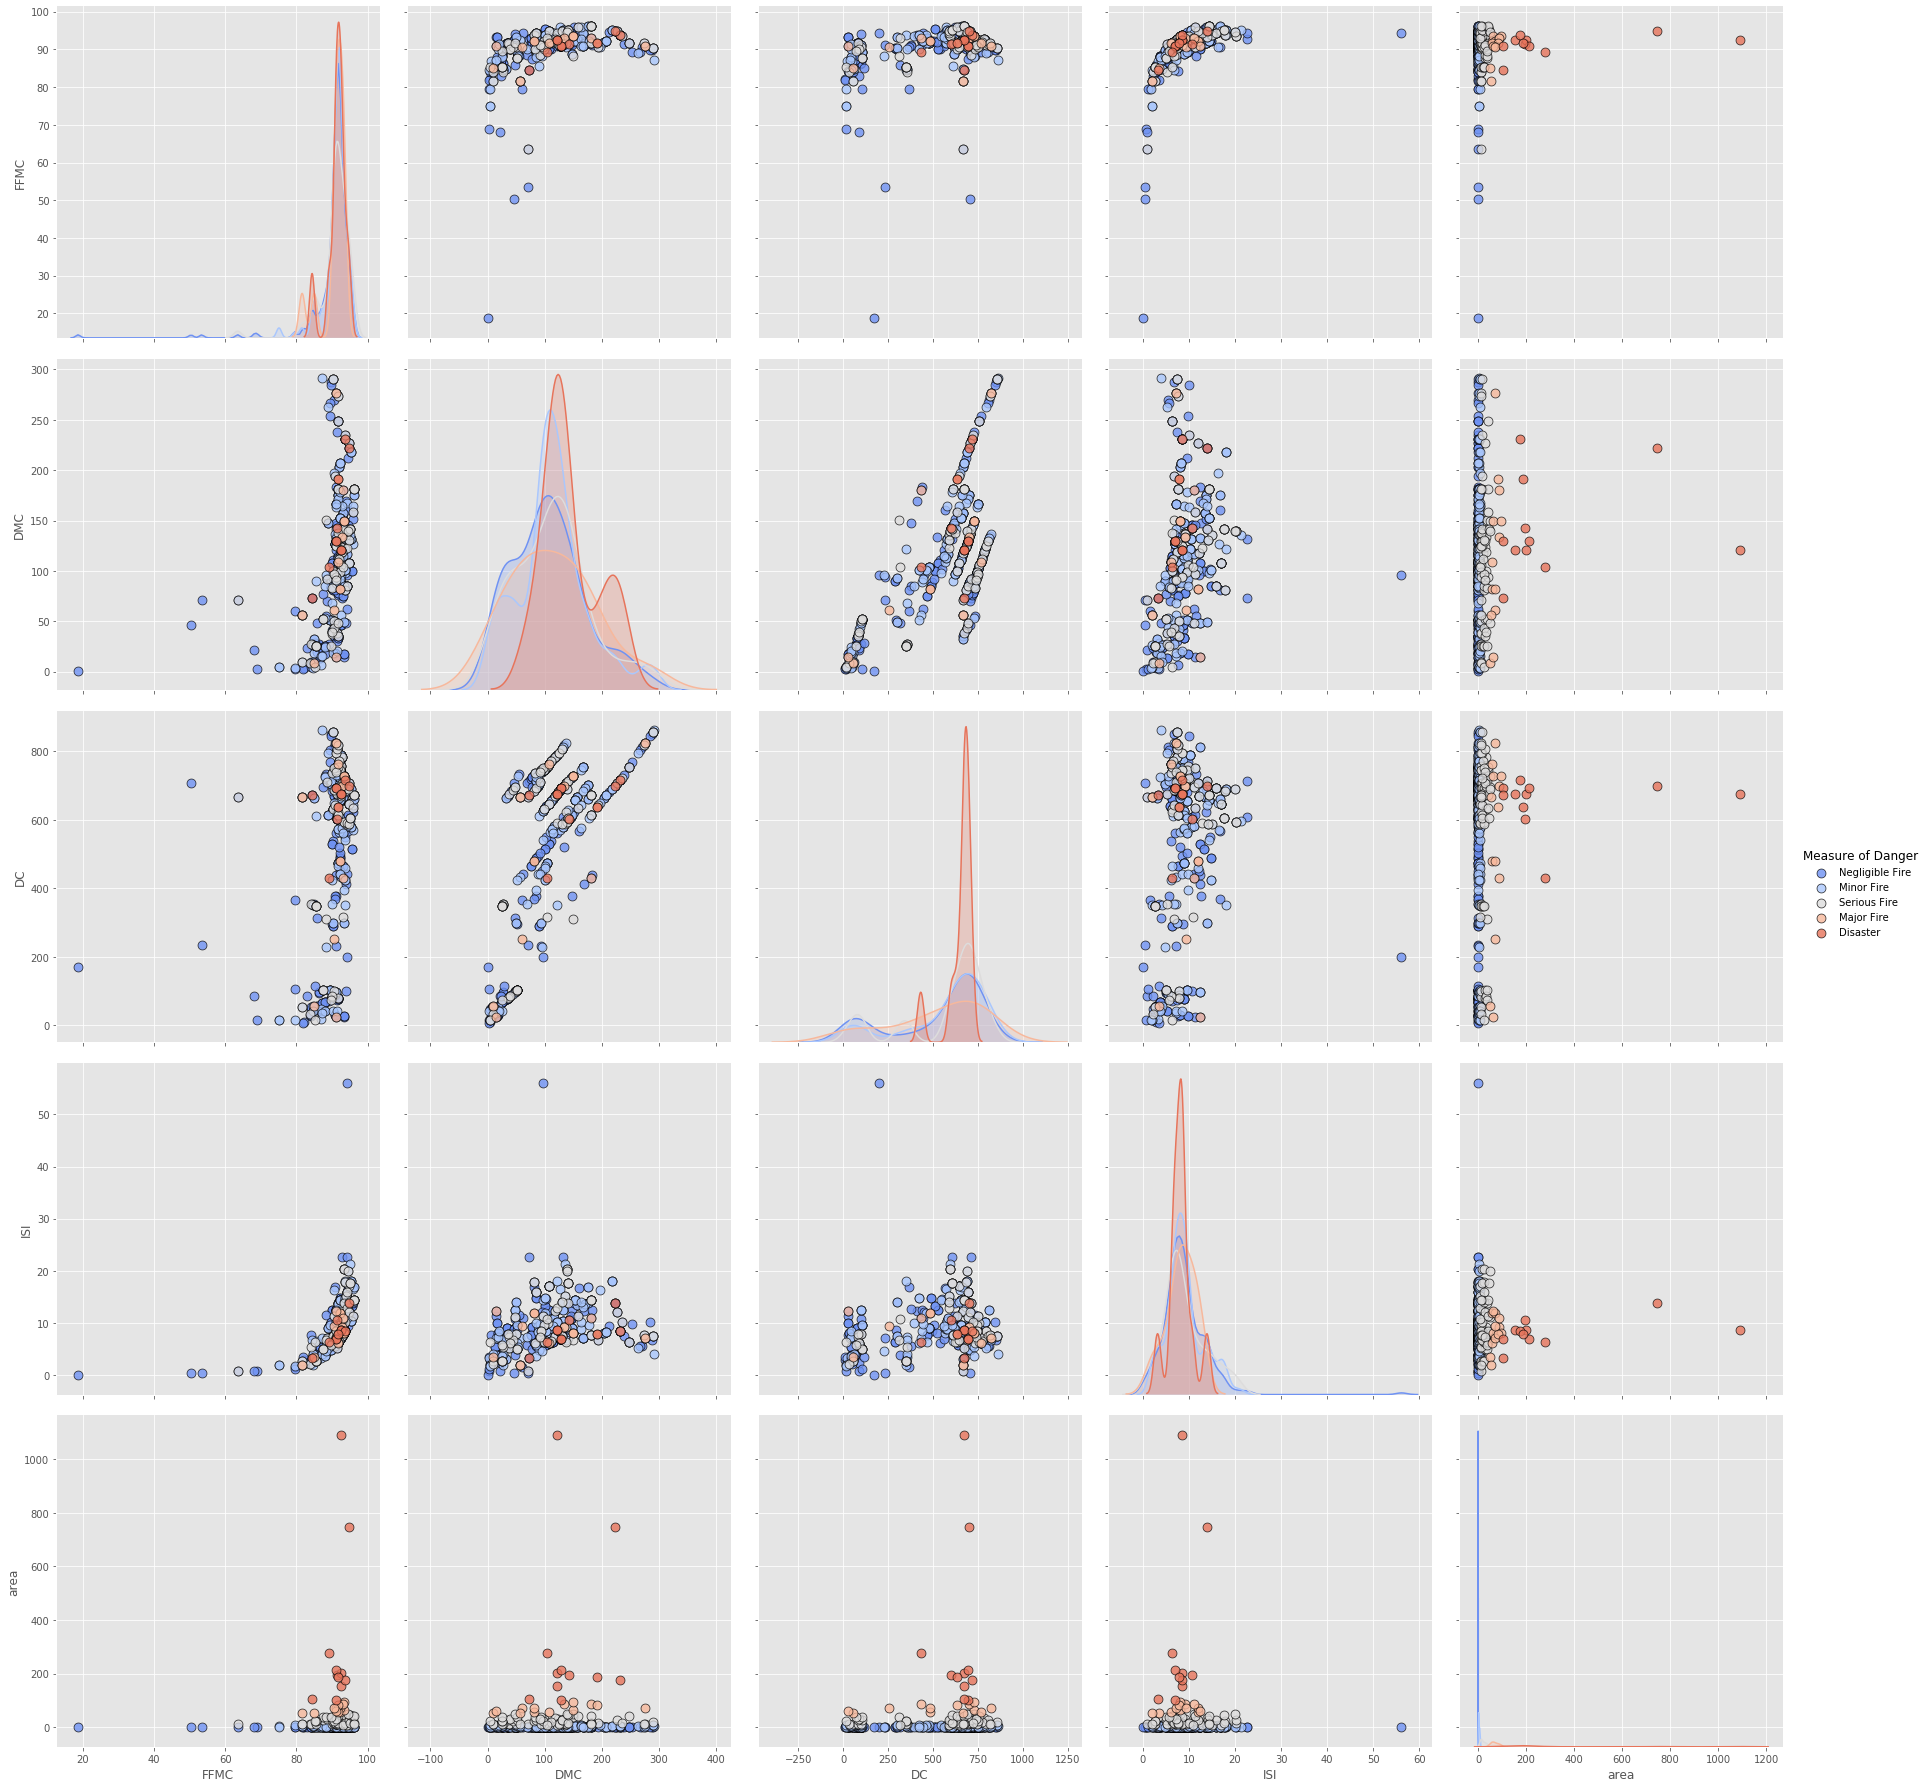

In [23]:
#Bi-variate analysis of FWI system variables.
sns.pairplot(fire_df,hue='Measure of Danger',palette='coolwarm', vars=['FFMC','DMC','DC','ISI','area'],height=5,plot_kws = {'alpha': 0.8, 's': 80, 'edgecolor': 'k'})
plt.show()

In [24]:
fire_df.columns

Index(['X', 'Y', 'month', 'day', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH',
       'wind', 'rain', 'area', 'Measure of Danger'],
      dtype='object')

C:\Users\Admin\Anaconda3\lib\site-packages\statsmodels\nonparametric\kde.py:487: RuntimeWarning: invalid value encountered in true_divide
  binned = fast_linbin(X, a, b, gridsize) / (delta * nobs)
C:\Users\Admin\Anaconda3\lib\site-packages\statsmodels\nonparametric\kdetools.py:34: RuntimeWarning: invalid value encountered in double_scalars
  FAC1 = 2*(np.pi*bw/RANGE)**2


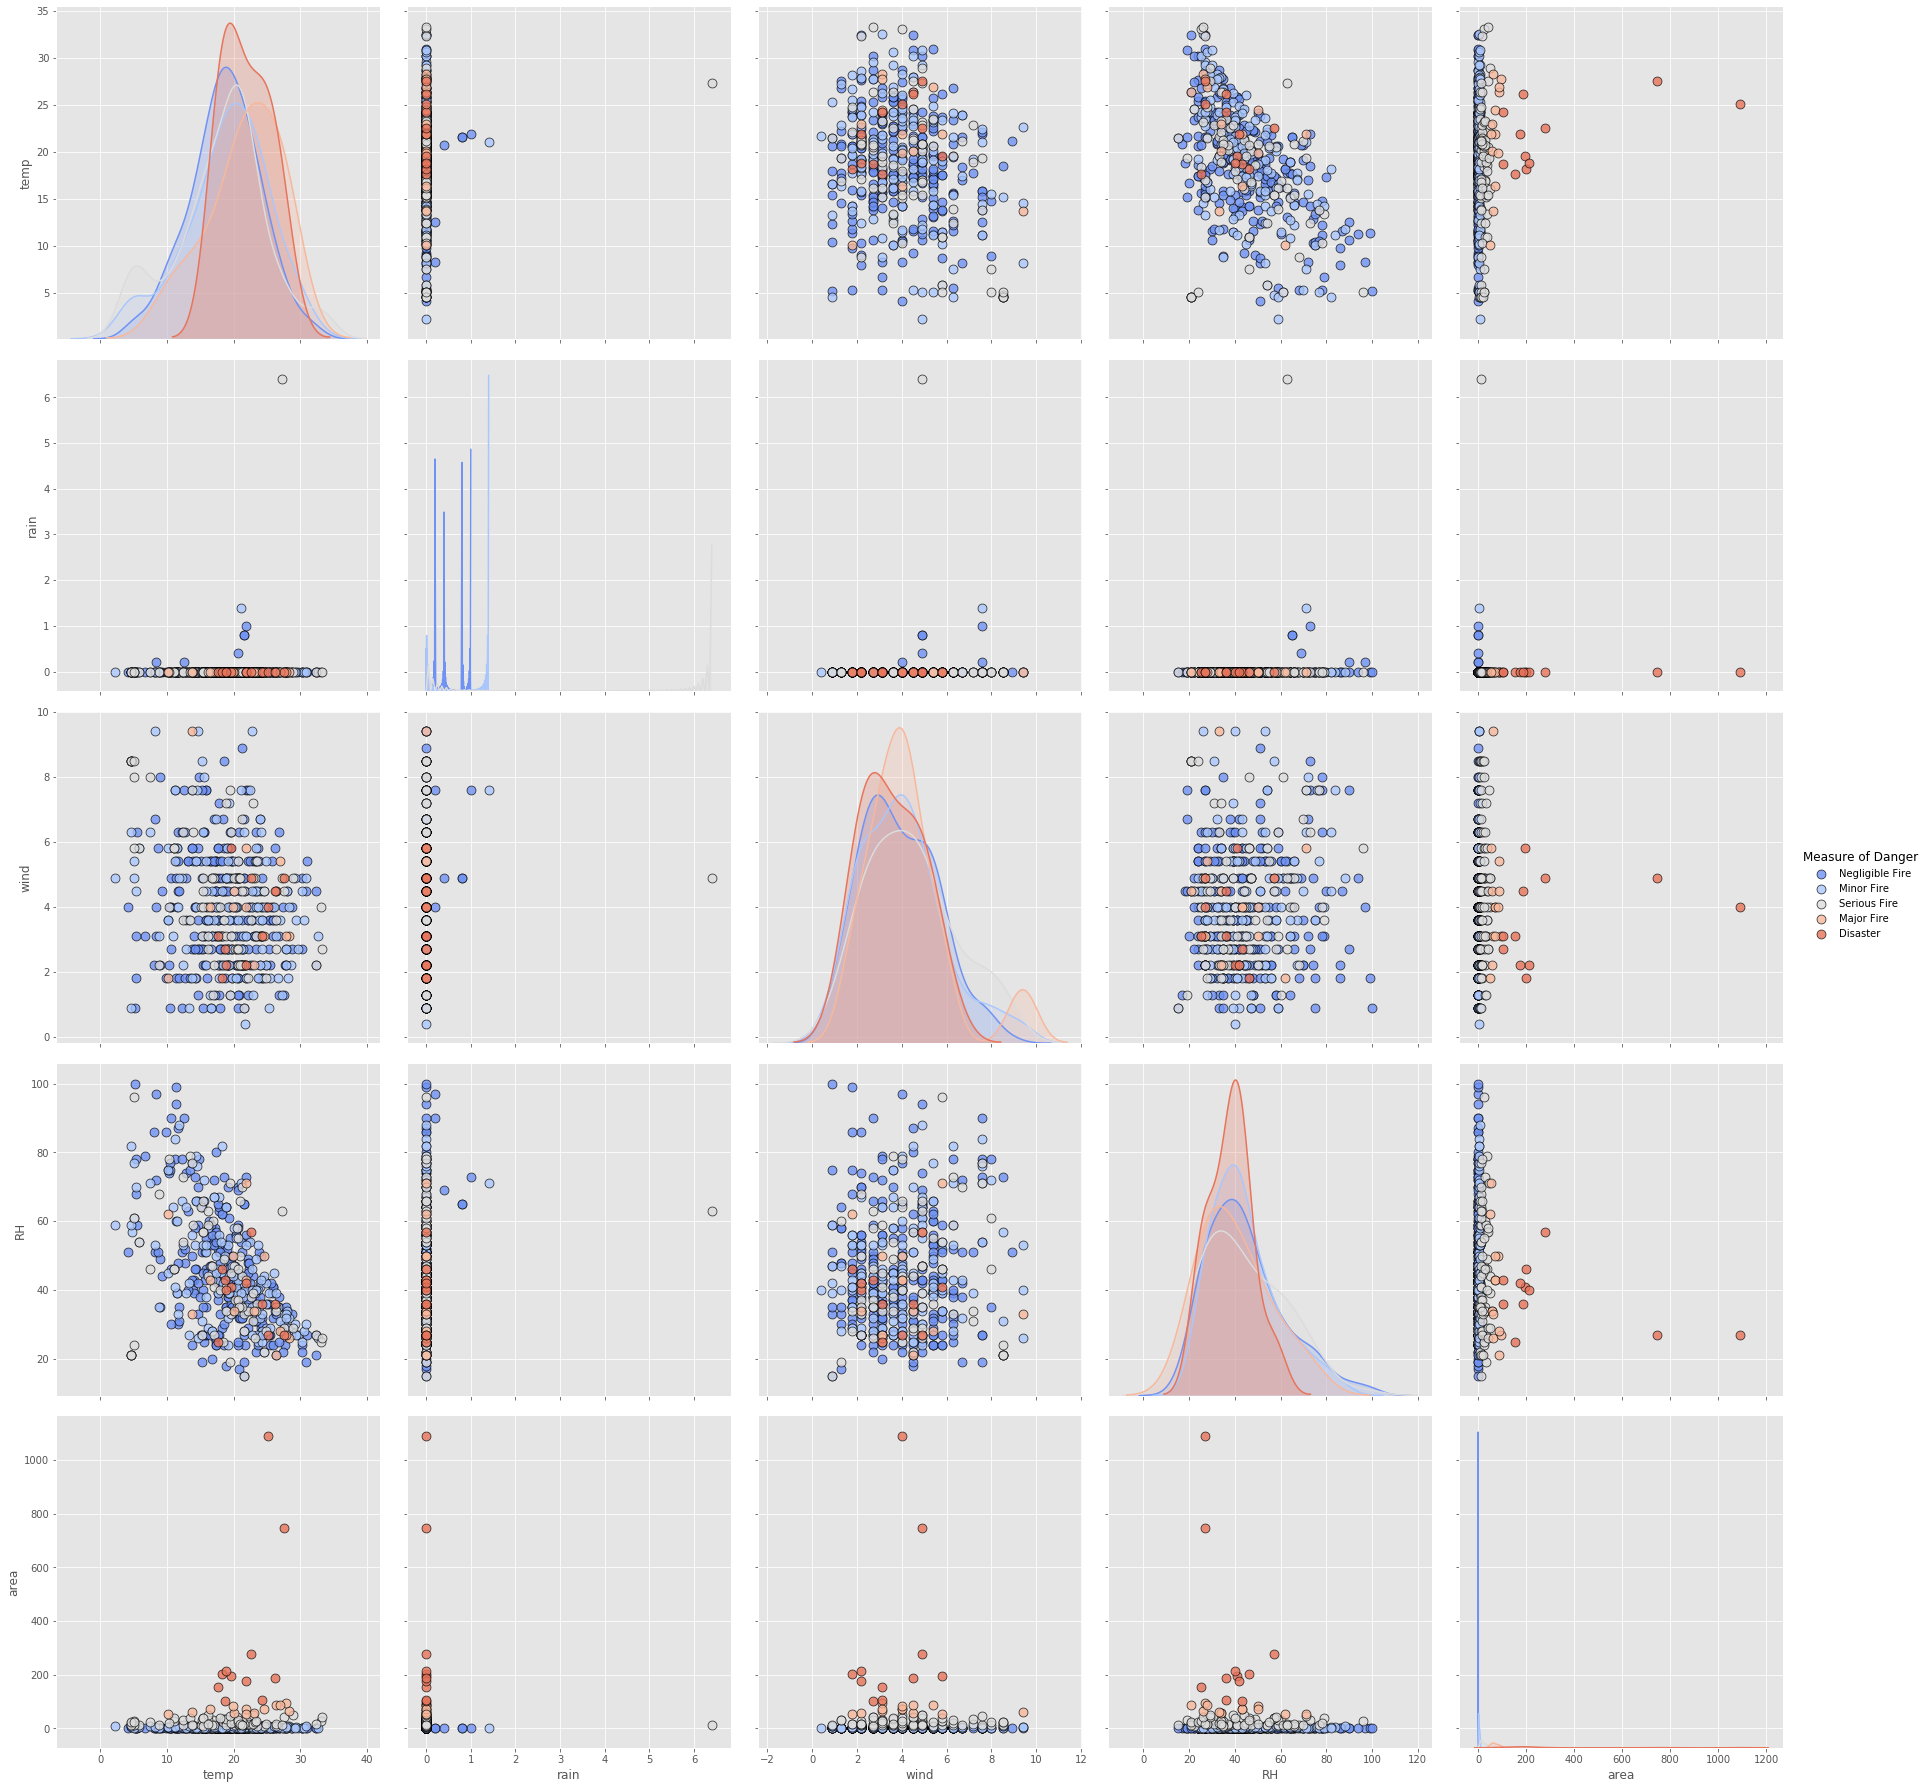

In [25]:
#Bi-variate analysis of meteorological variables.
sns.pairplot(fire_df,hue='Measure of Danger',palette='coolwarm', vars=['temp','rain','wind','RH','area'],height=5,plot_kws = {'alpha': 0.8, 's': 80, 'edgecolor': 'k'})
plt.show()

<font color='Purple'> **BONUS!!! -- Lesson from Climatology** </font>  <br>
Humidity is the amount of water vapour held by air. Relative Humidity (RH) is the percentage of water vapour held by air to the total amount of water vapour it can hold. When temperature of the air increases, its capacity to hold water vapour increases and thus Relative Humidity decreases. Using both the pairplot and correlation, check if your data set violated this natural phenomenon 


<font color='red'> **Challenges:** </font> 

5. There does not look a linear relationship between area and other features. Linear models may fail to fit the model accurately. 
6. There is multi collinearity between features --  **Temperature and RH, ISI and FFMC, DC and DMC.**
7. The burnt area is not correlated with any feature! 

# Blind Machine Learning Model. 
Let's run machine learning models without addressing any of the challenges. That will give us a **base line model**

In [26]:
#Encoding months and day data - Label

def replace_month(month):
    if month == 'jan':
        return(1) 
    elif month == 'feb':
        return(2)
    elif month == 'mar':
        return(3)
    elif month == 'apr':
        return(4)
    elif month == 'may':
        return(5)
    elif month == 'jun':
        return(6)
    elif month == 'jul':
        return(7)
    elif month == 'aug':
        return(8)
    elif month == 'sep':
        return(9)
    elif month == 'oct':
        return(10)
    elif month == 'nov':
        return(11)
    else:
        return(12)
    
def replace_day(day):
    if day == 'sun':
        return(7)
    elif day == 'mon':
        return(1)
    elif day == 'tue':
        return(2)
    elif day == 'wed':
        return(3)
    elif day == 'thu':
        return(4)
    elif day == 'fri':
        return(5)
    else:
        return(6)
    

In [27]:
from sklearn.model_selection import train_test_split


X = fire_df.drop(['area','Measure of Danger'],axis=1)
X['month'] = X['month'].apply(replace_month) #Encoding month
X['day'] = X['day'].apply(replace_day) #Encoding day
y = fire_df.area
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=0)


In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
LR= LinearRegression(fit_intercept = True, normalize = False, copy_X=True )
LR.fit(X_train,y_train) 
y_pred = LR.predict(X_test)
rmse_lr = mean_squared_error(y_test,y_pred,squared=False)
r2_lr = r2_score(y_test,y_pred)



In [29]:
print('The Root Mean Squared Error of the Model is',rmse_lr)
print('The R-Squared Value of the model is', r2_lr)


The Root Mean Squared Error of the Model is 132.29095710211618
The R-Squared Value of the model is -0.016687764871065935


## Assumptions of Linear Regression
We should also check if the Linear Regression model is satisfying the assumptions of Linear Regression. These are:
1. Linearity of model
2. No Multi-Collinearity
3. Homoscedasticity
4. No outliers
5. No high leverage points. 
6. No correlation between error terms. 
7. Residual errors should be normally distributed. 

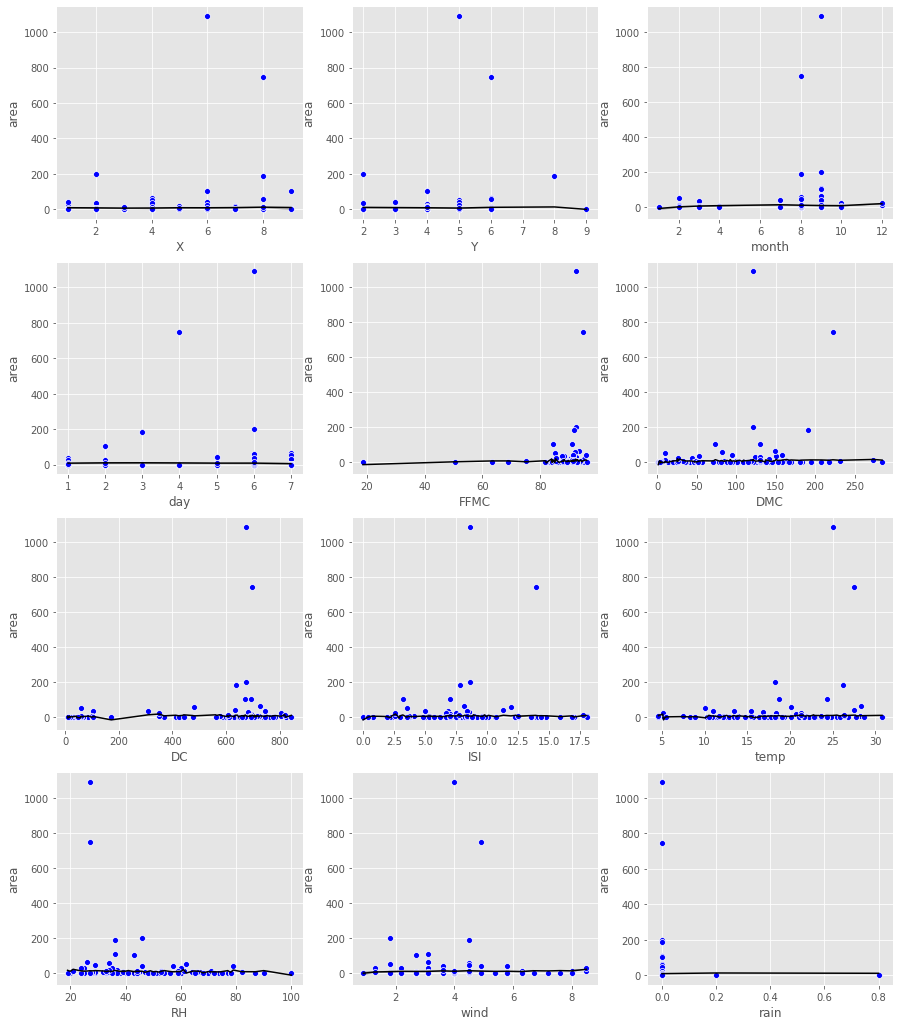

In [30]:
figure, axes = plt.subplots(4, 3, figsize=(15, 18),facecolor='white')
axes = axes.flatten()
index=0
for col in list(X_test.columns):
    sns.scatterplot(x=X_test[col], y=y_test,  color='blue',ax = axes[index])
    sns.lineplot(x=X_test[col], y=y_pred, color='black',ax = axes[index])
    index = index+1
plt.show()

<font color='red'> **LINEARITY ASSUMPTION FAILED!**</font> - We would require to do some transformation to solve this. <br>
<font color='red'> **PRESENCE OF OUTLIERS!**</font> - We should check if the outliers are errors and remove/impute them if they are erroneous values.      <br> 
<font color='red'> **PRESENCE OF HIGH LEVERAGE POINTS in rain, FFMC, ISI features!**</font> --  We should check if the high leverage points are errors and remove/impute them if they are erroneous values.  


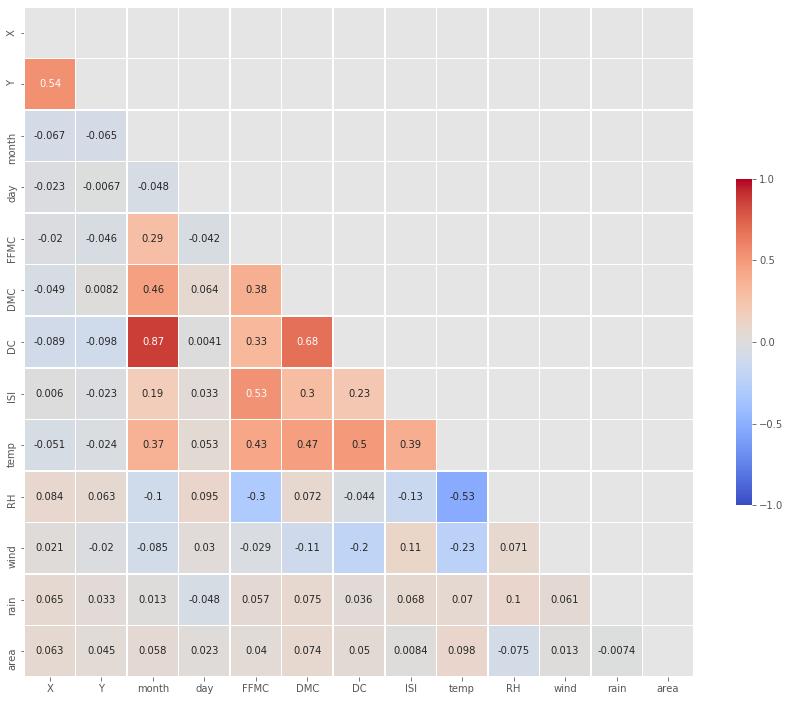

In [31]:
cor_mat = pd.concat([X,y],axis=1).corr()
mask = np.zeros_like(cor_mat, dtype=np.bool) #zero matrix of size cor_mat; all 0s become false
mask[np.triu_indices_from(mask)] = True #Upper triangle becomes true
plt.figure(figsize=(15,15))
ax = sns.heatmap(cor_mat, mask=mask, cmap='coolwarm',center=0, square=True, linewidths=0.5, annot=True, cbar_kws={'shrink': .4, 'ticks' : [-1, -.5, 0, 0.5, 1]}, vmin=-1, vmax=1)
bottom, top = ax.get_ylim()
ax.set_ylim(bottom + 0.5, top - 0.5)
plt.show()

In [32]:
from scipy.stats import pearsonr

#Threshold value for correlation
threshold = 0.5
corr_list = []
#Search for the highly correlated pairs
for i in range(0,cor_mat.shape[0]): 
    for j in range(i+1,cor_mat.shape[1]): #avoid repetition
        if (cor_mat.iloc[i,j] >= threshold)  or (cor_mat.iloc[i,j] <= -threshold):
            corr_list.append([cor_mat.iloc[i,j],i,j]) #store correlation and columns index

#Sort to show higher ones first            
s_corr_list = sorted(corr_list,key=lambda x: -abs(x[0]))

#Print correlations and column names
for v,i,j in s_corr_list:
    i = X.columns[i]
    j = X.columns[j]
    print ("Correlation Coefficient between '%s' and '%s' is: %.2f" % (i,j,v))
    print('P-Value is: ',pearsonr(X[i], X[j])[1])

Correlation Coefficient between 'month' and 'DC' is: 0.87
P-Value is:  2.2777029533845664e-157
Correlation Coefficient between 'DMC' and 'DC' is: 0.68
P-Value is:  2.264046980567338e-71
Correlation Coefficient between 'X' and 'Y' is: 0.54
P-Value is:  1.2513763931717688e-40
Correlation Coefficient between 'FFMC' and 'ISI' is: 0.53
P-Value is:  7.713525914304051e-39
Correlation Coefficient between 'temp' and 'RH' is: -0.53
P-Value is:  2.8111215284839443e-38


<font color='red'> **PRESENCE OF MULTI-COLLINEARITY.** </font>  - We would have to perform Feature Engineering to change these features or simply remove features that are collinear. 

C:\Users\Admin\Anaconda3\lib\site-packages\sklearn\utils\deprecation.py:144: FutureWarning: The sklearn.metrics.classification module is  deprecated in version 0.22 and will be removed in version 0.24. The corresponding classes / functions should instead be imported from sklearn.metrics. Anything that cannot be imported from sklearn.metrics is now part of the private API.
  warnings.warn(message, FutureWarning)


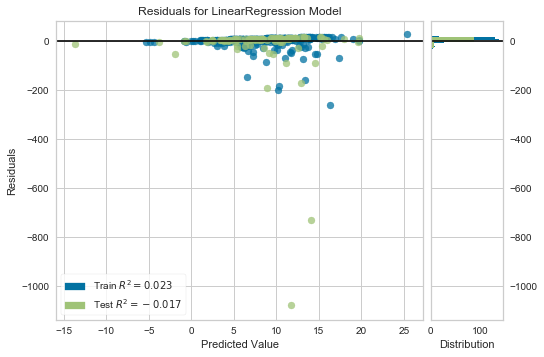

In [33]:
from yellowbrick.regressor import ResidualsPlot
visualiser = ResidualsPlot(LR)
visualiser.fit(X_train,y_train)
visualiser.score(X_test,y_test)
visualiser.poof()
plt.show()

Definitely there is no pattern in the residuals. But given the outliers, conclusively saying that there is homoscedasticity is not possible with the graph. We will use statistical test of **GOLDFLED-QUANDT TEST** to toest for homoscedastcity. 

Null Hypothesis (H0) = There is homoscedasticity i.e variance of residuals is constant. 
Alternative Hypothesis (H_alt) = There is heteroscedasticity. 

We will consider significance value (alpha) as 0.05. So, if the P-value of the test is **less than 0.05**, then we can **reject the null hypothesis** can say there is heteroscedasticity in the residual disribution. Otherwise, **we fail to reject the null hypothesis**

In [34]:
import statsmodels.stats.api as sms
name = ['F Stat','P-Value']
test = sms.het_goldfeldquandt(y_test-y_pred, X_test)
dict(zip(name, test))

{'F Stat': 2.2400394429671366, 'P-Value': 0.00637130163730651}

<font color='red'> **PRESENCE OF HETEROSCEDASTICITY IN RESIDUALS.** </font>  - Transforming the data and dealing with outliers can help us

C:\Users\Admin\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  after removing the cwd from sys.path.


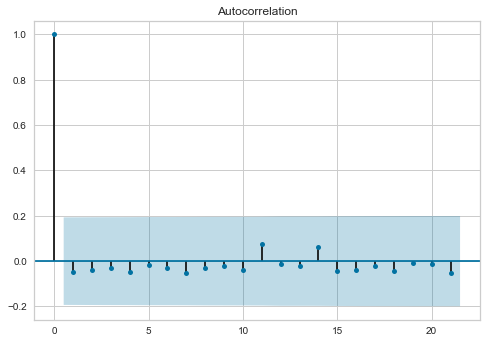

In [35]:
#Plotting autocorrelation function
import statsmodels.tsa.api as smt
acf = smt.graphics.plot_acf(y_test-y_pred , alpha=0.05)
acf.show()

In [36]:
from statsmodels.stats.stattools import durbin_watson
durbin_watson(y_test-y_pred)

2.0422641158154478

<font color='blue'> **NO AUTOCORRELATION BETWEEN ERRORS!!** </font> - A Durbin Watson score of 2 shows that the residuals are not correlated. You can even see this in the auto-correlation graph above. 


If we have to make any inference about the population data from the given sample data, then assuming that the sample belongs to a sampling distribution which is normally distributed is essential to perform inferential tests. In Linear regression, to veriy this assumption, we check if the residuals are normally distributed. This can be done by **QQ-Plots and Jarque Bera tests.** 

**JARQUE BERA:** Tests if the sample distribution has the same skewness and kurtosis as a normal distribution.
Null Hypothesis <br >(H0) : Residuals are normally distributed.<br>
Alternative Hypothesis (H_alt) : Residuals are not of normal distribution. 

If the P-value is less than 0.05 (alpha), then **we reject the null hypothesis**

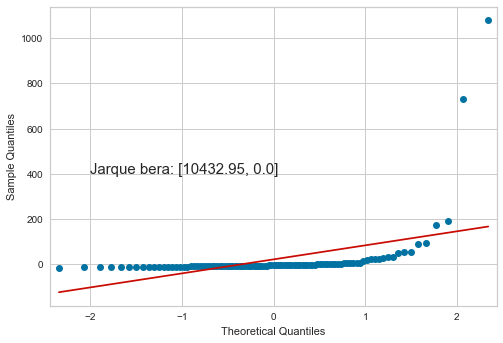

In [37]:
import statsmodels.api as sm
from scipy.stats import jarque_bera
sm.qqplot(y_test-y_pred,line ='r')
jb = [round(n,2) for n in jarque_bera(y_test-y_pred)]
plt.annotate(xy=(-2,400),s = f"Jarque bera: {jb}",fontsize=15)
plt.show()

<font color='red'> **RESIDUALS ARE NOT NORMALLY DISTRIBUTED** </font> 

Very evidently, both from the graph and the Jarque bera test, we see that the residuals are not normally distributed. However, given that our sample size is 517, we can apply **central limit theorem** to say that the sampling distribution will be normal. 

<font color='red'> **Issues with this model** </font> 
1. High RMSE value. 
2. Near 0 R2 value means that variance in the target variable is not being explained by the feature variables. You can see from the graph that this model cannot explain the high forest burnt area. 
3. Except autocorrelation, none of the other assumptions have been met.


In [38]:
from sklearn.svm import SVR

svr = SVR(kernel = 'linear')
svr.fit(X_train,y_train) 
y_pred = svr.predict(X_test)
rmse_svr = mean_squared_error(y_test,y_pred,squared=False)
r2_svr = r2_score(y_test,y_pred)

print('The Root Mean Squared Error of the Model is',rmse_svr)
print('The R-Squared Value of the model is', r2_svr)

The Root Mean Squared Error of the Model is 134.29354238907868
The R-Squared Value of the model is -0.04770143726764231


In [39]:
from sklearn.tree import DecisionTreeRegressor

Tree = DecisionTreeRegressor()
Tree.fit(X_train,y_train) 
y_pred = Tree.predict(X_test)
rmse_dt = mean_squared_error(y_test,y_pred,squared=False)
r2_dt = r2_score(y_test,y_pred)

print('The Root Mean Squared Error of the Model is',rmse_dt)
print('The R-Squared Value of the model is', r2_dt)

The Root Mean Squared Error of the Model is 135.29215018237704
The R-Squared Value of the model is -0.06334080065581249


In [40]:
model_table=pd.DataFrame([[rmse_lr,r2_lr],[rmse_svr,r2_svr],[rmse_dt,r2_dt]],columns=['RMSE','R2'],index=['Linear Regression','SVM','Decision Tree'])
model_table

,RMSE,R2
Linear Regression,132.290957,-0.016688
SVM,134.293542,-0.047701
Decision Tree,135.292150,-0.063341


None of the three models have a satisfactory performance. We will now try to address few of the challenges in the dataset to improve the model performance. 
1. We will first normalise the data and check if we can eliminate skewness.
2. Apply transformations if necessary

In [41]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler() 

feat_scaled = scaler.fit_transform(pd.concat([fire_df[numerical_columns],fire_df.area],axis=1))
feat_scaled = pd.DataFrame(feat_scaled,columns=['FFMC', 'RH', 'ISI', 'DMC', 'wind', 'DC', 'temp', 'rain','area'])
feat_scaled.head()

,FFMC,RH,ISI,DMC,wind,DC,temp,rain,area
0,0.423529,0.700000,0.086492,0.870968,0.192926,0.00000,0.090909,0.101325,0.0
1,0.211765,0.055556,0.118194,0.927742,0.508039,0.00000,0.119430,0.775419,0.0
2,0.211765,0.100000,0.146795,0.927742,0.398714,0.00000,0.119430,0.796294,0.0
3,0.964706,0.400000,0.110958,0.941935,0.196141,0.03125,0.160428,0.081623,0.0
4,0.988235,0.155556,0.172984,0.910968,0.295820,0.00000,0.171123,0.110590,0.0


In [42]:
X.sample(5)
#feat_scaled.shape

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain
164,8,5,9,7,89.7,90.0,704.4,4.8,17.8,67,2.2,0.0
201,6,5,3,7,90.1,37.6,83.7,7.2,12.4,54,3.6,0.0
234,4,5,9,6,92.5,121.1,674.4,8.6,17.7,25,3.1,0.0
231,1,5,9,7,93.5,149.3,728.6,8.1,27.8,27,3.1,0.0
382,8,6,8,3,95.2,217.7,690.0,18.0,28.2,29,1.8,0.0


In [43]:
X = pd.concat([X[['X','Y','month','day']].reset_index(),feat_scaled.drop('area',axis=1).reset_index()],axis=1)
X.drop(['index'],axis=1,inplace=True)
y= feat_scaled.area
X.head()

,X,Y,month,day,FFMC,RH,ISI,DMC,wind,DC,temp,rain
0,7,5,3,5,0.423529,0.700000,0.086492,0.870968,0.192926,0.00000,0.090909,0.101325
1,7,4,10,2,0.211765,0.055556,0.118194,0.927742,0.508039,0.00000,0.119430,0.775419
2,7,4,10,6,0.211765,0.100000,0.146795,0.927742,0.398714,0.00000,0.119430,0.796294
3,8,6,3,5,0.964706,0.400000,0.110958,0.941935,0.196141,0.03125,0.160428,0.081623
4,8,6,3,7,0.988235,0.155556,0.172984,0.910968,0.295820,0.00000,0.171123,0.110590


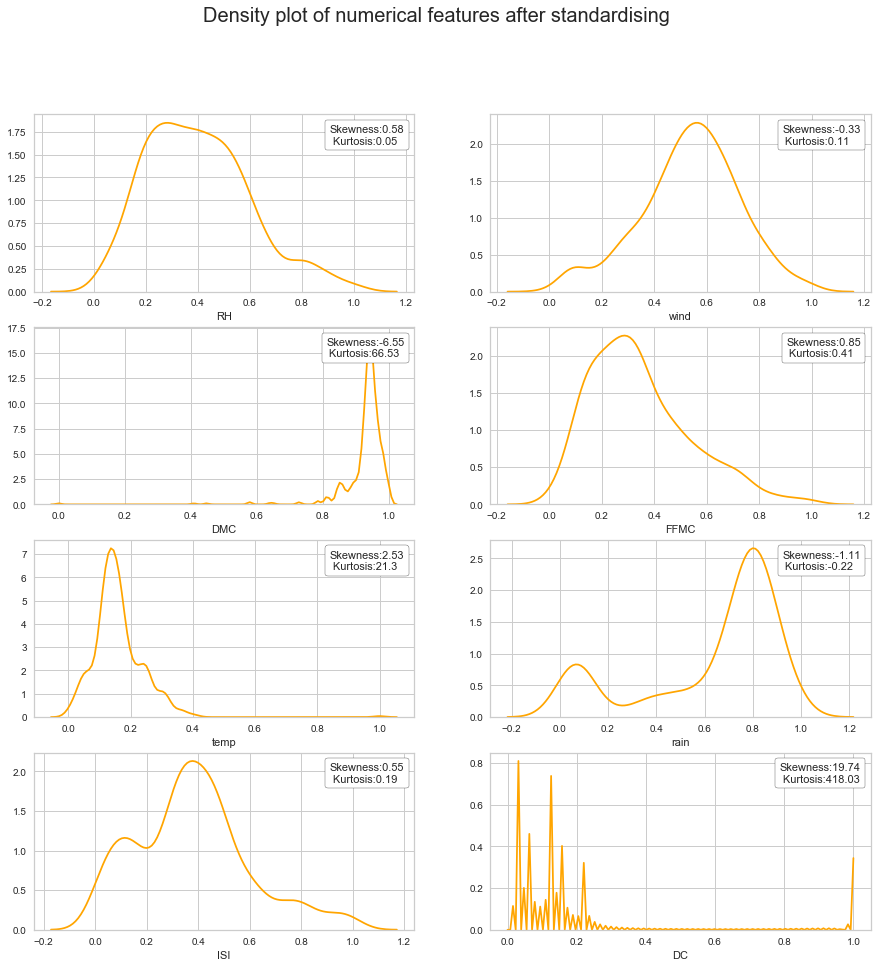

In [44]:
from matplotlib.offsetbox import AnchoredText
fig, ax = plt.subplots(4, 2, figsize=(15, 15),squeeze=True)
ax = ax.flatten()
index = 0
fig.suptitle('Density plot of numerical features after standardising ',size=20)

for i in numerical_columns:
    p1 = sns.distplot(X[i], kde=True, color = 'orange',ax=ax[index],hist=False)
    at = AnchoredText('Skewness:'+str(round(X[i].skew(),2))+"\n Kurtosis:"+str(round(X[i].kurtosis(),2)), prop=dict(size=11), frameon=True, loc='upper right')
    at.patch.set_boxstyle("round,pad=0.,rounding_size=0.2")
    p1.add_artist(at)
    index +=1
plt.show()

Skew: 12.802213419146318
Kurtosis: 192.7339123337094


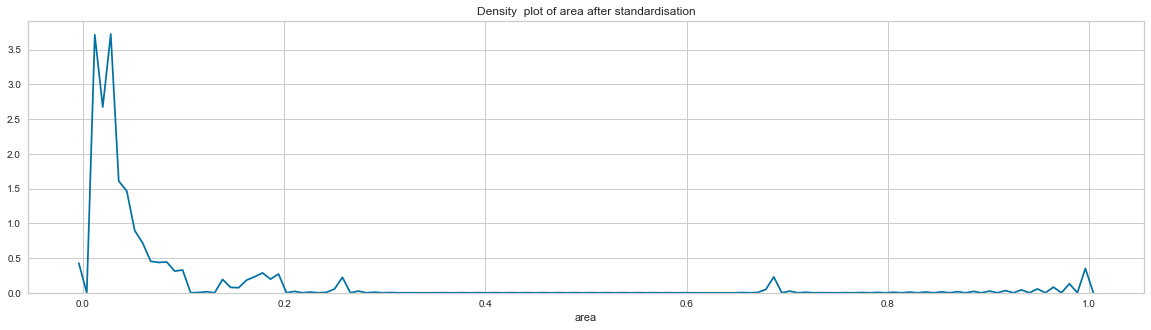

In [45]:
plt.figure(figsize=(20,5))
print("Skew: {}".format(y.skew()))
print("Kurtosis: {}".format(y.kurtosis()))
sns.distplot(y, kde=True, hist=False)
plt.title('Density  plot of area after standardisation')
plt.show()

Skew: 1.2584408784086476
Kurtosis: 1.1042535580907975


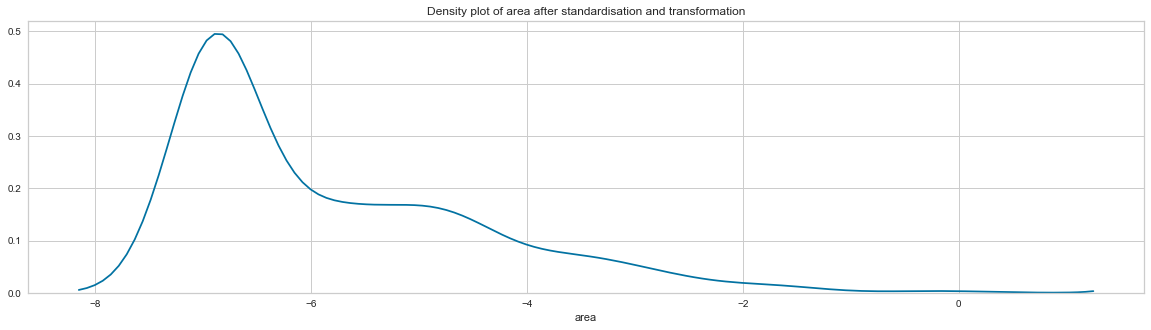

In [46]:
#Lets apply transformations as few features are still skewed. Also we will have to remember all the transformations and scalings we have done to retrieve the final output. 
y_log = np.log(y+0.001)

plt.figure(figsize=(20,5))
print("Skew: {}".format(y_log.skew()))
print("Kurtosis: {}".format(y_log.kurtosis()))
sns.distplot(y_log, kde=True, hist=False)
plt.title('Density plot of area after standardisation and transformation')
plt.show()

In [47]:
import math

X['FFMC_tr'] = (2/math.pi)*np.arcsin(X.FFMC)  #Best transformation selected after many trial and error
X['ISI_tr'] = np.log(X.ISI+0.1)  #Best transformation selected after many trial and error.
X['rain_tr'] = np.log(X.rain+0.1) #Best transformation selected after many trial and error. But even this is not satisfactory as you will see ahead. 

transformed_columns = ['FFMC_tr', 'ISI_tr','rain_tr']

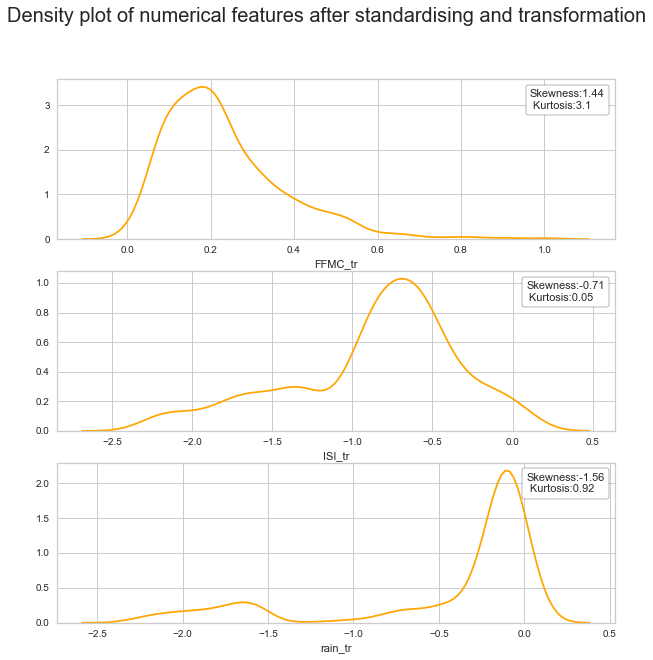

In [48]:
fig, ax = plt.subplots(3, 1, figsize=(10, 10),squeeze=True)
ax = ax.flatten()
index = 0
fig.suptitle('Density plot of numerical features after standardising and transformation',size=20)

for i in transformed_columns:
    p1 = sns.distplot(X[i], kde=True, color = 'orange',ax=ax[index],hist=False)
    at = AnchoredText('Skewness:'+str(round(X[i].skew(),2))+"\n Kurtosis:"+str(round(X[i].kurtosis(),2)), prop=dict(size=11), frameon=True, loc='upper right')
    at.patch.set_boxstyle("round,pad=0.,rounding_size=0.2")
    p1.add_artist(at)
    index +=1
plt.show()

Despite many trials, rain feature could not be transformed into less skew-kurtosis distribution. We will thus remove this feature so that model is not affected by the outliers present in it. <br>

Now let's one-hot encode our categorical variables.

In [49]:
X_enc = pd.get_dummies(fire_df[categorical_columns])
X_enc.shape

(513, 21)

In [50]:
#Now our feature dataset would be:
X = pd.concat([X_enc.reset_index(),X[['FFMC_tr','ISI_tr','RH','DMC','wind','DC','temp']].reset_index()],axis=1)
X.drop(['index'],axis=1,inplace=True)
X.head()

,X,Y,month_apr,month_aug,month_dec,month_feb,month_jan,month_jul,month_jun,month_mar,...,day_thu,day_tue,day_wed,FFMC_tr,ISI_tr,RH,DMC,wind,DC,temp
0,7,5,0,0,0,0,0,0,0,1,...,0,0,0,0.278418,-1.679367,0.700000,0.870968,0.192926,0.00000,0.090909
1,7,4,0,0,0,0,0,0,0,0,...,0,1,0,0.135842,-1.522369,0.055556,0.927742,0.508039,0.00000,0.119430
2,7,4,0,0,0,0,0,0,0,0,...,0,0,0,0.135842,-1.399196,0.100000,0.927742,0.398714,0.00000,0.119430
3,8,6,0,0,0,0,0,0,0,1,...,0,0,0,0.830359,-1.556096,0.400000,0.941935,0.196141,0.03125,0.160428
4,8,6,0,0,0,0,0,0,0,1,...,0,0,0,0.902251,-1.298342,0.155556,0.910968,0.295820,0.00000,0.171123


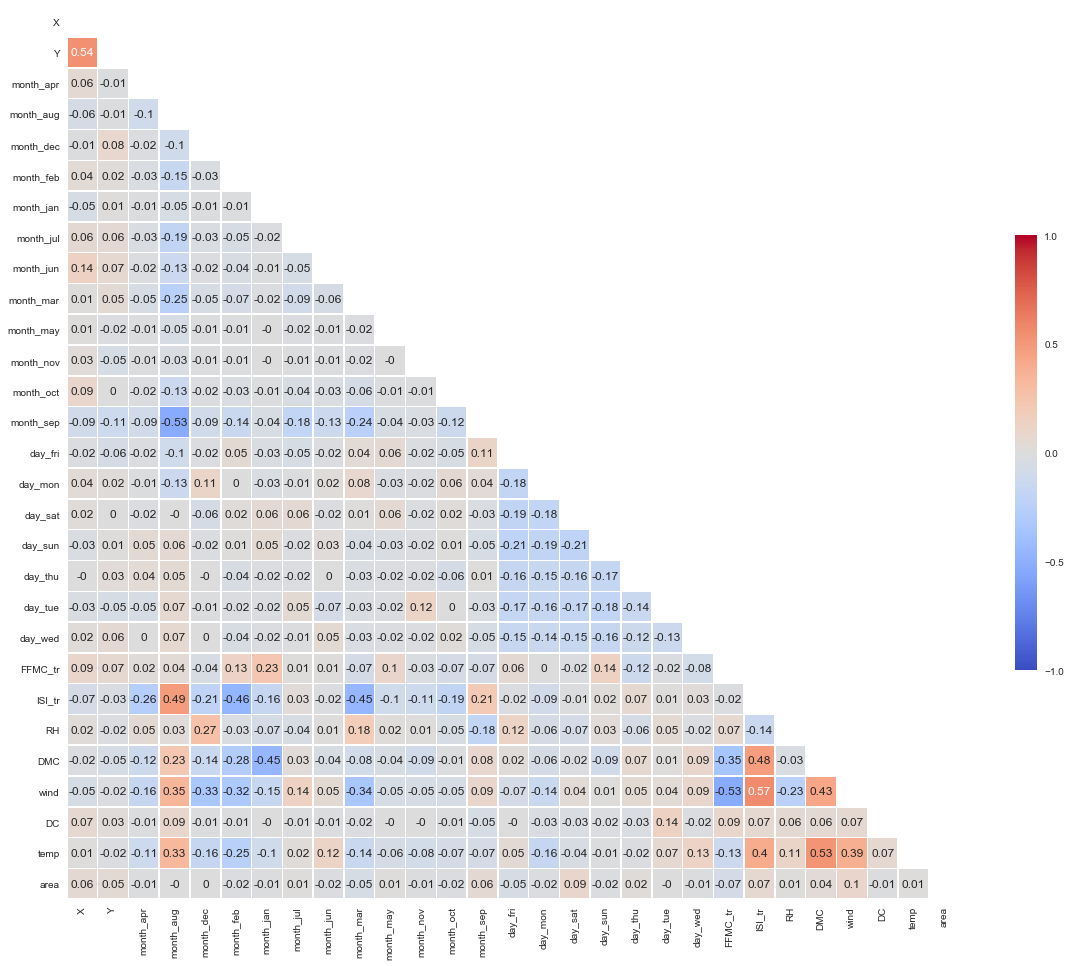

In [51]:
#Let's check if correlations have changed
cor_mat = round(pd.concat([X,y],axis=1).corr(),2)
mask = np.zeros_like(cor_mat, dtype=np.bool) #zero matrix of size cor_mat; all 0s become false
mask[np.triu_indices_from(mask)] = True #Upper triangle becomes true
plt.figure(figsize=(20,20))
ax = sns.heatmap(cor_mat, mask=mask, cmap='coolwarm',center=0, square=True, linewidths=0.5, annot=True, cbar_kws={'shrink': .4, 'ticks' : [-1, -.5, 0, 0.5, 1]}, vmin=-1, vmax=1)
bottom, top = ax.get_ylim()
ax.set_ylim(bottom + 0.5, top - 0.5)
plt.show()

In [52]:
from scipy.stats import pearsonr

#Threshold value for correlation
threshold = 0.5
corr_list = []
#Search for the highly correlated pairs
for i in range(0,cor_mat.shape[0]): 
    for j in range(i+1,cor_mat.shape[1]): #avoid repetition
        if (cor_mat.iloc[i,j] >= threshold)  or (cor_mat.iloc[i,j] <= -threshold):
            corr_list.append([cor_mat.iloc[i,j],i,j]) #store correlation and columns index

#Sort to show higher ones first            
s_corr_list = sorted(corr_list,key=lambda x: -abs(x[0]))

#Print correlations and column names
for v,i,j in s_corr_list:
    i = X.columns[i]
    j = X.columns[j]
    print ("Correlation Coefficient between '%s' and '%s' is: %.2f" % (i,j,v))
    print('P-Value is: ',pearsonr(X[i], X[j])[1])

Correlation Coefficient between 'ISI_tr' and 'wind' is: 0.57
P-Value is:  3.889262367626207e-46
Correlation Coefficient between 'X' and 'Y' is: 0.54
P-Value is:  1.2513763931717688e-40
Correlation Coefficient between 'month_aug' and 'month_sep' is: -0.53
P-Value is:  6.039285317611755e-38
Correlation Coefficient between 'FFMC_tr' and 'wind' is: -0.53
P-Value is:  8.063265245842134e-38
Correlation Coefficient between 'DMC' and 'temp' is: 0.53
P-Value is:  7.713525914304051e-39


In [53]:
vif=pd.DataFrame()
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif['VIF Factor'] = [variance_inflation_factor(X[['FFMC_tr','ISI_tr','RH','DMC','DC','temp','wind']].values, i) for i in range(X[['FFMC_tr','ISI_tr','RH','DMC','DC','temp','wind']].shape[1])]
vif['Features'] = X[['FFMC_tr','ISI_tr','RH','DMC','DC','temp','wind']].columns
vif.sort_values(by='VIF Factor',ascending=False)

,VIF Factor,Features
3,51.312998,DMC
6,20.037797,wind
5,6.949441,temp
2,5.530703,RH
1,4.884586,ISI_tr
0,4.442724,FFMC_tr
4,1.034686,DC


Thus we will remove the following features:
1. FFMC_tr
2. temp
3. DC

In [54]:
X = X.drop(['FFMC_tr','temp','DC'],axis=1)

In [55]:
X.head()

,X,Y,month_apr,month_aug,month_dec,month_feb,month_jan,month_jul,month_jun,month_mar,...,day_mon,day_sat,day_sun,day_thu,day_tue,day_wed,ISI_tr,RH,DMC,wind
0,7,5,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,-1.679367,0.700000,0.870968,0.192926
1,7,4,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,-1.522369,0.055556,0.927742,0.508039
2,7,4,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,-1.399196,0.100000,0.927742,0.398714
3,8,6,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,-1.556096,0.400000,0.941935,0.196141
4,8,6,0,0,0,0,0,0,0,1,...,0,0,1,0,0,0,-1.298342,0.155556,0.910968,0.295820


In [56]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=0)
numerical_columns = ['ISI_tr','RH','DMC','wind']

In [57]:
LR.fit(X_train,y_train) 
y_pred_lr = LR.predict(X_test)
rmse_lr = mean_squared_error(y_test,y_pred_lr,squared=False)
r2_lr = r2_score(y_test,y_pred_lr)

print('The Root Mean Squared Error of the Model is',rmse_lr)
print('The R-Squared Value of the model is', r2_lr)

The Root Mean Squared Error of the Model is 0.12148619550065286
The R-Squared Value of the model is -0.020242129317826763


In [58]:
svr.fit(X_train,y_train) 
y_pred_svr = svr.predict(X_test)
rmse_svr = mean_squared_error(y_test,y_pred_svr,squared=False)
r2_svr = r2_score(y_test,y_pred_svr)

print('The Root Mean Squared Error of the Model is',rmse_svr)
print('The R-Squared Value of the model is', r2_svr)

The Root Mean Squared Error of the Model is 0.1335846495151921
The R-Squared Value of the model is -0.23356631110826398


In [59]:
Tree.fit(X_train,y_train) 
y_pred_dt = Tree.predict(X_test)
rmse_dt = mean_squared_error(y_test,y_pred_dt,squared=False)
r2_dt = r2_score(y_test,y_pred_dt)

print('The Root Mean Squared Error of the Model is',rmse_dt)
print('The R-Squared Value of the model is', r2_dt)

The Root Mean Squared Error of the Model is 0.12386701204064254
The R-Squared Value of the model is -0.06062219866913754


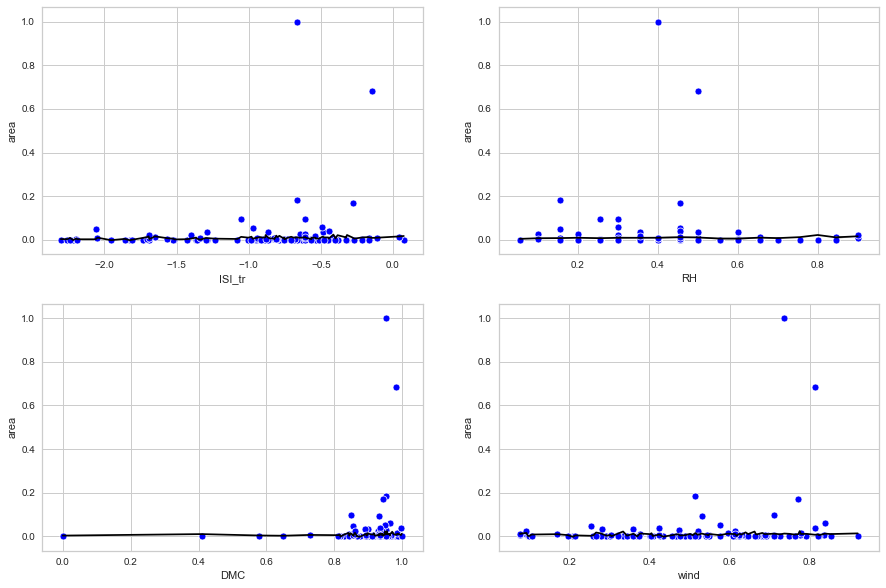

In [60]:
#Linear Regression
figure, axes = plt.subplots(2, 2, figsize=(15, 10),facecolor='white')
axes = axes.flatten()
index=0
for col in list(X_test[numerical_columns].columns):
    sns.scatterplot(x=X_test[col], y=y_test,  color='blue',ax = axes[index])
    sns.lineplot(x=X_test[col], y=y_pred_lr, color='black',ax = axes[index])
    index = index+1
plt.show()

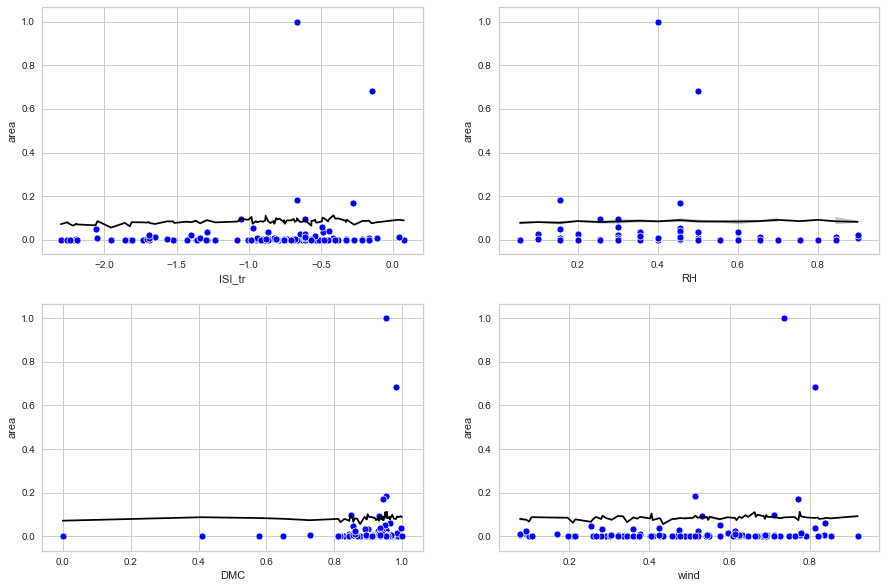

In [61]:
#SVM
figure, axes = plt.subplots(2, 2, figsize=(15, 10),facecolor='white')
axes = axes.flatten()
index=0
for col in list(X_test[numerical_columns].columns):
    sns.scatterplot(x=X_test[col], y=y_test,  color='blue',ax = axes[index])
    sns.lineplot(x=X_test[col], y=y_pred_svr, color='black',ax = axes[index])
    index = index+1
plt.show()

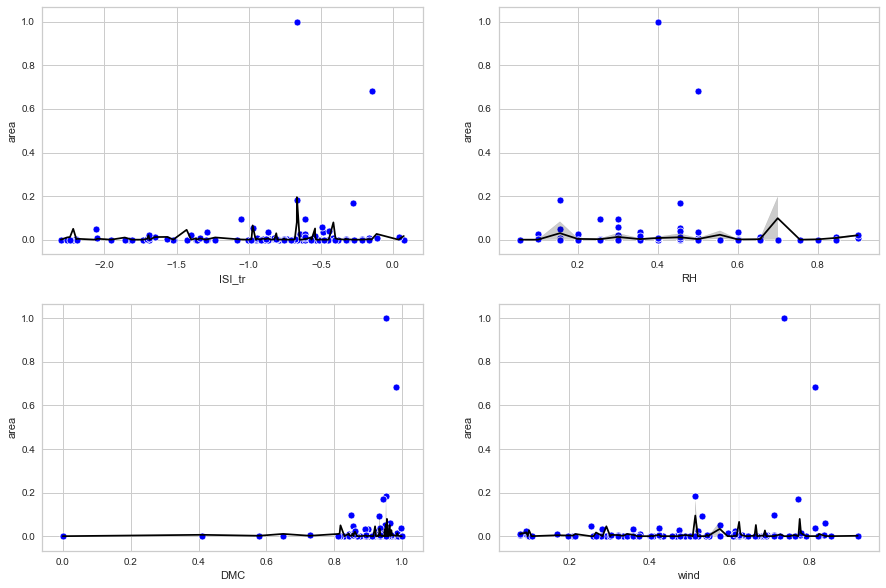

In [62]:
#DecisionTree
figure, axes = plt.subplots(2, 2, figsize=(15, 10),facecolor='white')
axes = axes.flatten()
index=0
for col in list(X_test[numerical_columns].columns):
    sns.scatterplot(x=X_test[col], y=y_test,  color='blue',ax = axes[index])
    sns.lineplot(x=X_test[col], y=y_pred_dt, color='black',ax = axes[index])
    index = index+1
plt.show()

Numerical features are failing to explain the variance in the forest fires. However, it ooks like DMC feature in the SCM model, helps to explain little bit more than the rest. We will now perform RFE to select the best features of SVR any way.

From now on we will stick to the SVM model. 

In [63]:
from sklearn.feature_selection import RFE
rfe = RFE(svr, 5)
fit = rfe.fit(X_train, y_train)
print("Model Feature Ranking:", fit.ranking_)
# calculate the score for the selected features
feature_names = np.array(X.columns)
print('Most important features (RFE): %s'% feature_names[rfe.support_])

Model Feature Ranking: [10  5 14  4 13 12 11  2 15 16 18 20 21  9 17  1  7  8  3  6 19  1  1  1
  1]
Most important features (RFE): ['day_mon' 'ISI_tr' 'RH' 'DMC' 'wind']


In [64]:
imp_feat = ['month_jul','month_sep','RH','ISI_tr','wind','DMC']  
X = X[imp_feat]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=0)

In [65]:
svr.fit(X_train,y_train) 
y_pred_svr = svr.predict(X_test)
rmse_svr = mean_squared_error(y_test,y_pred_svr,squared=False)
r2_svr = r2_score(y_test,y_pred_svr)

print('The Root Mean Squared Error of the Model is',rmse_svr)
print('The R-Squared Value of the model is', r2_svr)

The Root Mean Squared Error of the Model is 0.13702235773360238
The R-Squared Value of the model is -0.2978731912465058


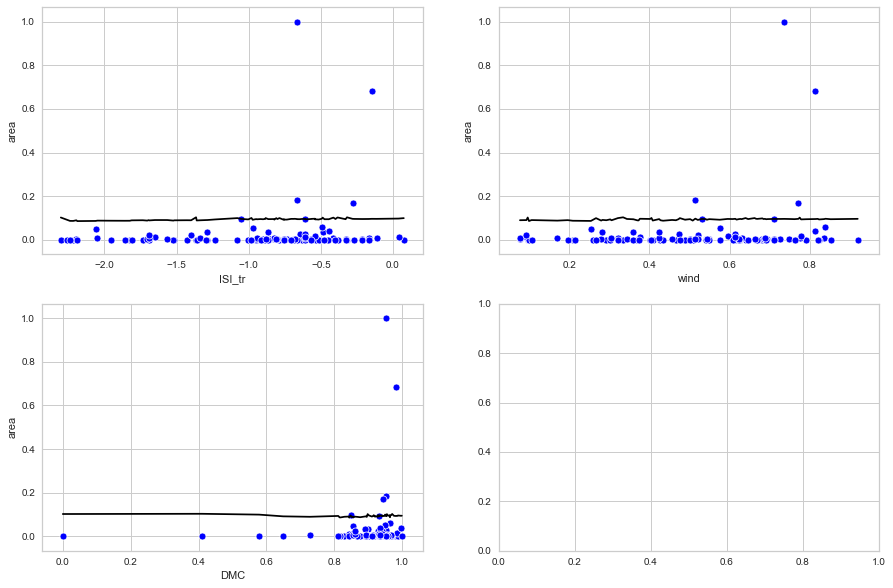

In [66]:
figure, axes = plt.subplots(2, 2, figsize=(15, 10),facecolor='white')
axes = axes.flatten()
index=0
for col in list(['ISI_tr','wind','DMC']):
    sns.scatterplot(x=X_test[col], y=y_test,  color='blue',ax = axes[index])
    sns.lineplot(x=X_test[col], y=y_pred_svr, color='black',ax = axes[index])
    index = index+1
plt.show()

No great change in the performance. We could possible remove the outliers for a better fit, but that would defeat the purpose of warning the Forest Service Officer regarding an impending disaster. 

# Conclusion
From this analysis we have the following insights to mitigate forest fires:

1. More vigilance is needed in the months of August and September, especially on weekends. 
2. As human factor (on weekends) appears to be a reason behind forest fires, eco-tourism should be regulated. No Cigarettes, camp-fires should be allowed. 
3. Whenever FFMC is high (>80) and ISI is low (<20), there are threats of disastrous forest fires. So forest department should be cautious when these indicators are in this range. 

Finally, more data should be collected about forest fires to avoid the present skewness in the data. That would help us use Machine Learning models more accurately. 